In [ ]:
# https://github.com/fracpete/employees-db-sqlite

# pip install -U langchain langchain-ollama, langchain-community langchain-core faiss-cpu

In [2]:
"""
SQL Agent with Dedicated Tools using create_agent
Using employees db database with create_agent approach
"""

import re

# Core imports
from langchain_ollama import ChatOllama
from langchain_community.utilities import SQLDatabase
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage
from langchain.agents import create_agent

from dotenv import load_dotenv
load_dotenv()


True

In [3]:
# ============================================================================
# STEP 1: DATABASE SETUP
# ============================================================================
print("Setting up employees database...")


# Connect to employees database
db = SQLDatabase.from_uri("sqlite:///db/employees_db-full-1.0.6.db")

# Check connection and get basic info
try:
    # Test connection by getting table names
    tables = db.get_usable_table_names()
    print(f"✓ Database connected successfully")
    print(f"✓ Found {len(tables)} tables: {', '.join(tables)}")
    
except Exception as e:
    print(f"✗ Database connection failed: {e}")

# Get schema information
SCHEMA = db.get_table_info()
# print("\nDatabase Schema:", SCHEMA)
print("✓ Connected to employees database")


Setting up employees database...
✓ Database connected successfully
✓ Found 6 tables: departments, dept_emp, dept_manager, employees, salaries, titles
✓ Connected to employees database


In [4]:
tables

['departments', 'dept_emp', 'dept_manager', 'employees', 'salaries', 'titles']

In [5]:
db.run("SELECT name FROM sqlite_master WHERE type='table';")

"[('departments',), ('dept_emp',), ('dept_manager',), ('employees',), ('salaries',), ('titles',)]"

In [6]:
db.run("select count(*) from employees")

'[(300024,)]'

In [7]:

# ============================================================================
# STEP 2: MODELS SETUP
# ============================================================================
# Using ChatOllama
llm = ChatOllama(
    model="qwen3:0.6b", 
    base_url="http://localhost:11434",
    temperature=0
)

response = llm.invoke("Hello, how are you?")
response.pretty_print()
print("✓ Initialized Ollama chat model")


================================== Ai Message ==================================

Hello! How are you? 😊 I'm here to help! What can I do for you today?
✓ Initialized Ollama chat model


In [8]:

# ============================================================================
# STEP 3: SQL TOOLS - One for each step
# ============================================================================

@tool
def get_database_schema(table_name: str = None) -> str:
    """Get database schema information for SQL query generation.
    Use this first to understand table structure before creating queries."""
    print(f"🔍 Getting schema for: {table_name if table_name else 'all tables'}")
    
    if table_name:
        try:
            # Get specific table info
            tables = db.get_usable_table_names()
            if table_name.lower() in [t.lower() for t in tables]:
                result = db.get_table_info([table_name])
                print(f"✓ Retrieved schema for table: {table_name}")
                return result
            else:
                return f"Error: Table '{table_name}' not found. Available tables: {', '.join(tables)}"
        except Exception as e:
            return f"Error getting table info: {e}"
    else:
        # Get all schema info
        print("✓ Retrieved full database schema")
        return SCHEMA


In [9]:
result = get_database_schema.invoke({'table_name': 'departments'})
print(result)

🔍 Getting schema for: departments
✓ Retrieved schema for table: departments

CREATE TABLE departments (
	dept_no CHAR(4) NOT NULL, 
	dept_name VARCHAR(40) NOT NULL, 
	PRIMARY KEY (dept_no), 
	UNIQUE (dept_name)
)

/*
3 rows from departments table:
dept_no	dept_name
d009	Customer Service
d005	Development
d002	Finance
*/


In [10]:

@tool
def generate_sql_query(question: str, schema_info: str = None) -> str:
    """Generate a SQL SELECT query from a natural language question using database schema.
    Always use this after getting schema information."""
    print(f"🔧 Generating SQL for: {question[:100]}...")
    
    # Use provided schema or get full schema
    schema_to_use = schema_info if schema_info else SCHEMA
    
    prompt = f"""
                Based on this database schema:
                {schema_to_use}

                Generate a SQL query to answer this question: {question}

                Rules:
                - Use only SELECT statements
                - Include only existing columns and tables
                - Add appropriate WHERE, GROUP BY, ORDER BY clauses as needed
                - Limit results to 10 rows unless specified otherwise
                - Use proper SQL syntax for SQLite

                Return only the SQL query, nothing else.
                """
    
    try:
        response = llm.invoke(prompt)
        query = response.content.strip()
        print(f"✓ Generated SQL query")
        return query
    except Exception as e:
        return f"Error generating query: {e}"


In [21]:
result = generate_sql_query.invoke({"question": "what is maximum salary in employees"})
print(result)

🔧 Generating SQL for: what is maximum salary in employees...
✓ Generated SQL query
SELECT MAX(salary) FROM salaries;


In [22]:
db.run("SELECT MAX(salary) FROM salaries;")

'[(158220,)]'

Examples Query:

```sql
SELECT MAX(salary) FROM salaries;
```

In [11]:
@tool
def validate_sql_query(query: str) -> str:
    """Validate SQL query for safety and syntax before execution.
    Returns 'Valid: <query>' if safe or 'Error: <message>' if unsafe."""
    print(f"🔍 Validating SQL: {query[:100]}...")
    
    # Clean up the query
    clean_query = query.strip()
    
    # Remove SQL code block markers if present
    clean_query = re.sub(r'```sql\s*', '', clean_query, flags=re.IGNORECASE)
    clean_query = re.sub(r'```\s*', '', clean_query)
    clean_query = clean_query.strip().rstrip(";")
    
    # Check 1: Must be a SELECT statement
    if not clean_query.lower().startswith("select"):
        return "Error: Only SELECT statements are allowed"
    
    # Check 2: Block dangerous SQL keywords
    dangerous_keywords = ['INSERT', 'UPDATE', 'DELETE', 'ALTER', 'DROP', 'CREATE', 'TRUNCATE']
    query_upper = clean_query.upper()
    
    for keyword in dangerous_keywords:
        if keyword in query_upper:
            return f"Error: {keyword} operations are not allowed"
    
    print("✓ Query validation passed")
    return f"Valid: {clean_query}"

In [ ]:
result = validate_sql_query.invoke({"query": "SELECT MAX(salary) FROM salaries;"})
print(result)

# wrong query test
result = validate_sql_query.invoke({"query": "Update MAX(salary) FROM salaries;"})
print(result)

🔍 Validating SQL: SELECT MAX(salary) FROM salaries;...
✓ Query validation passed
Valid: SELECT MAX(salary) FROM salaries
🔍 Validating SQL: Update MAX(salary) FROM salaries;...
Error: Only SELECT statements are allowed


In [12]:

@tool
def execute_sql_query(query: str) -> str:
    """Execute a validated SQL query and return results.
    Only use this after validating the query for safety."""
    print(f"🚀 Executing SQL: {query[:100]}...")
    
    try:
        # Clean the query
        clean_query = query.strip()
        if clean_query.startswith("Valid: "):
            clean_query = clean_query[7:]  # Remove "Valid: " prefix
        
        clean_query = re.sub(r'```sql\s*', '', clean_query, flags=re.IGNORECASE)
        clean_query = re.sub(r'```\s*', '', clean_query)
        clean_query = clean_query.strip().rstrip(";")
        
        # Execute query
        result = db.run(clean_query)
        print("✓ Query executed successfully")
        
        if result:
            return f"Query Results:\n{result}"
        else:
            return "Query executed successfully but returned no results."
            
    except Exception as e:
        error_msg = f"Execution Error: {str(e)}"
        print(f"✗ {error_msg}")
        return error_msg


In [27]:
execute_sql_query.invoke({"query": "SELECT MAX(salary) FROM salaries;"})

🚀 Executing SQL: SELECT MAX(salary) FROM salaries;...
✓ Query executed successfully


'Query Results:\n[(158220,)]'

In [13]:
@tool
def fix_sql_error(original_query: str, error_message: str, question: str) -> str:
    """Fix a failed SQL query by analyzing the error and generating a corrected version.
    Use this when validation or execution fails."""
    print(f"🔧 Fixing SQL error: {error_message[:100]}...")
    
    fix_prompt = f"""
                    The following SQL query failed:
                    Query: {original_query}
                    Error: {error_message}
                    Original Question: {question}

                    Database Schema:
                    {SCHEMA}

                    Analyze the error and provide a corrected SQL query that:
                    1. Fixes the specific error mentioned
                    2. Still answers the original question
                    3. Uses only valid table and column names from the schema
                    4. Follows SQLite syntax rules

                    Return only the corrected SQL query, nothing else.
                    """
    
    try:
        response = llm.invoke(fix_prompt)
        fixed_query = response.content.strip()
        print("✓ Generated fixed SQL query")
        return fixed_query
    except Exception as e:
        return f"Error generating fix: {e}"


In [14]:
# ALT + Z -> for soft wrap
fix_sql_error.invoke({"original_query": "Update MAX(salary) FROM salaries;", "error_message": "Error: Only SELECT statements are allowed", "question": "what is maximum salary in employees"})

🔧 Fixing SQL error: Error: Only SELECT statements are allowed...
✓ Generated fixed SQL query


'SELECT MAX(salary) FROM salaries;'

In [15]:
# ============================================================================
# STEP 4: SYSTEM PROMPT
# ============================================================================

SQL_SYSTEM_PROMPT = f"""You are an expert SQL analyst working with an employees database.

Database Schema:
{SCHEMA}

Your workflow for answering questions:
1. Use `get_database_schema` first to understand available tables and columns (if needed)
2. Use `generate_sql_query` to create SQL based on the question
3. Use `validate_sql_query` to check the query for safety and syntax
4. Use `execute_sql_query` to run the validated query
5. If there's an error, use `fix_sql_error` to correct it and try again (up to 3 times)
6. Provide a clear answer based on the query results

Rules:
- Always follow the workflow step by step
- If a query fails, use the fix tool and try again
- Provide clear, informative answers
- Be precise with table and column names
- Handle errors gracefully and try to fix them
- If you fail after 3 attempts, explain what went wrong

Available tools for each step:
- get_database_schema: Get table structure info
- generate_sql_query: Create SQL from question
- validate_sql_query: Check query safety/syntax  
- execute_sql_query: Run the query
- fix_sql_error: Fix failed queries

Remember: Always validate queries before executing them for safety.
"""

In [16]:
# ============================================================================
# STEP 5: CREATE AGENT
# ============================================================================

# All tools for the agent
tools = [
    get_database_schema,
    generate_sql_query,
    validate_sql_query, 
    execute_sql_query,
    fix_sql_error
]

# Create the SQL agent using create_agent
sql_agent = create_agent(
    llm, 
    tools, 
    system_prompt=SQL_SYSTEM_PROMPT
)

print("✓ Created SQL agent with create_agent")

✓ Created SQL agent with create_agent


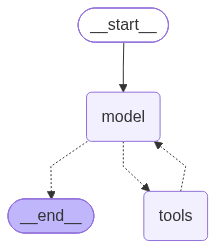

In [17]:
sql_agent

In [18]:

# ============================================================================
# STEP 6: QUERY FUNCTIONS 
# ============================================================================

def ask_sql(question: str):
    """Ask the SQL agent a question using the full workflow."""
    print(f"\n{'='*60}")
    print(f"SQL AGENT - Question: {question}")
    print('='*60)
    
    for event in sql_agent.stream({"messages": question},stream_mode="values"):
        msg = event["messages"][-1]
        
        # Show tool usage
        if hasattr(msg, 'tool_calls') and msg.tool_calls:
            for tc in msg.tool_calls:
                print(f"\n🔧 Using Tool: {tc['name']}")
                print(f"Args: {str(tc['args'])[:200]}")
        
        # Show final answer
        elif hasattr(msg, 'content') and msg.content:
            print(f"\n💬 Answer:\n{msg.content}")


In [36]:
ask_sql("What is the average salary of employees in the Sales department?")


SQL AGENT - Question: What is the average salary of employees in the Sales department?

💬 Answer:
What is the average salary of employees in the Sales department?

🔧 Using Tool: get_database_schema
Args: {'table_name': 'departments'}
🔍 Getting schema for: departments
✓ Retrieved schema for table: departments

💬 Answer:

CREATE TABLE departments (
	dept_no CHAR(4) NOT NULL, 
	dept_name VARCHAR(40) NOT NULL, 
	PRIMARY KEY (dept_no), 
	UNIQUE (dept_name)
)

/*
3 rows from departments table:
dept_no	dept_name
d009	Customer Service
d005	Development
d002	Finance
*/

🔧 Using Tool: generate_sql_query
Args: {'question': 'What is the average salary of employees in the Sales department?', 'schema_info': 'CREATE TABLE departments (\n\tdept_no CHAR(4) NOT NULL, \n\tdept_name VARCHAR(40) NOT NULL, \n\tPRIMARY
🔧 Generating SQL for: What is the average salary of employees in the Sales department?...
✓ Generated SQL query

💬 Answer:
SELECT AVG(salary) AS average_salary
FROM employees
JOIN departments 

In [2]:
# ============================================================================
# INTERACTIVE CHAT
# ============================================================================
def chat():
    """Start an interactive chat with the SQL agent."""
    print("\n🤖 Text-to-SQL Chat - Type 'quit', 'q' or 'exit' to exit")
    
    while True:
        question = input("\nYour question: ").strip()
        if question.lower() in ['quit', 'exit', 'q']:
            break
        if question:
            ask_sql(question)

chat() 


🤖 Text-to-SQL Chat - Type 'quit', 'q' or 'exit' to exit
